# 🌿 PlantSeg Disease Classifier — Google Colab Pipeline

Пайплайн для тренування моделі розпізнавання хвороб рослин на датасеті **PlantSeg**
(Wei et al., 2024 — *"A Large-Scale In-the-wild Dataset for Plant Disease Segmentation"*,
Zenodo record [13762907](https://zenodo.org/records/13762907)).

**Що робить цей ноутбук:**
1. Автоматично завантажує та розпаковує PlantSeg (3.0 GB) прямо в Colab.
2. Досліджує структуру датасету (`Metadata.csv`, `images/`, `annotations/`, `json/`, train/test).
3. Будує PyTorch `Dataset`/`DataLoader` для задачі **класифікації хвороби** (Plant+Disease → 115+ класів),
   з опційним використанням masks (`annotations/`) як допоміжного сигналу (attention / focal-crop).
4. Тренує baseline-модель (Model v1, опис нижче) на GPU.
5. Логує метрики: **Accuracy, macro-F1, macro ROC-AUC (OvR), Precision/Recall, confusion matrix**,
   а також їхню динаміку по епохах.
6. Проводить **stratified k-fold крос-валідацію**.
7. Автоматично прогонятиме **до 10 конфігурацій гіперпараметрів** (backbone / optimizer / LR /
   scheduler / augmentation / label smoothing), обираючи найкращу за композитним score
   (mean of Accuracy, macro-F1, macro ROC-AUC). Зупиняється, коли досягнуто ≥ 95% або
   вичерпано 10 спроб — залежно від того, що настане раніше.
8. Зберігає найкращу модель (ваги `.pth` + `label_encoder.json` + `config.json`) — можна
   завантажити локально й відтворити інференс без Colab.
9. Дає окрему клітинку для **тесту на випадковому фото** (з test-спліту або власного завантаженого файлу).

> ⚠️ Перед першим запуском: `Runtime → Change runtime type → GPU (T4/A100)`.


## 0. Model v1 — характеристики (Model Card)

*(За запитом — опис англійською нижче для документації/звіту.)*

```
MODEL v1 — BASELINE SPECIFICATION
----------------------------------------------------------------
Task:                Multi-class image classification
                      (fine-grained plant disease recognition)
Backbone:             EfficientNet-B0 (ImageNet-1k pretrained, via `timm`)
Head:                 GlobalAvgPool -> Dropout(0.3) -> Linear(1280 -> num_classes)
Input resolution:     224 x 224 (resized + center/random crop)
Normalization:        ImageNet mean/std
Loss:                 CrossEntropyLoss (label_smoothing configurable, default 0.1)
Optimizer:            AdamW, lr=3e-4, weight_decay=1e-4 (baseline; swept in HPO stage)
LR schedule:          CosineAnnealingLR
Batch size:            32 (Colab T4 friendly; 64 on A100)
Epochs (baseline):    15 (HPO trials use fewer epochs — 6-8 — for search speed)
Augmentation:         RandomResizedCrop, HorizontalFlip, ColorJitter, Rotation(±15°),
                      CoarseDropout (via albumentations)
Class balancing:      WeightedRandomSampler (inverse class frequency)
Regularization:       Dropout 0.3, weight decay, label smoothing, early stopping (patience=5)
Mixed precision:      torch.cuda.amp (speeds up ~1.6-2x on T4)
Params:               ~5.3M (EfficientNet-B0 backbone) + classifier head
Target metrics:       Accuracy, macro-F1, macro ROC-AUC (OvR) >= 0.95 (goal, not guaranteed —
                      115 fine-grained, imbalanced, in-the-wild classes are hard)
Cross-validation:     Stratified K-Fold (k=5, optionally reduced to k=3 for time budget)
Reproducibility:      seed=42 fixed for numpy/torch/random; deterministic cudnn where possible
----------------------------------------------------------------
```

## 1. Середовище: GPU, залежності

In [1]:
# Перевірка GPU
!nvidia-smi -L
import torch
print("CUDA available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")


GPU 0: Tesla T4 (UUID: GPU-c899e978-087d-c647-feaf-a0835081a4c6)
CUDA available: True
Device: Tesla T4


In [2]:
# Встановлення залежностей (deterministic pinning не робимо, щоб не конфліктувати з Colab preinstalled torch)
!pip -q install timm==1.0.9 albumentations==1.4.15 opencv-python-headless==4.10.0.84 \
    scikit-learn==1.5.2 seaborn==0.13.2 imagehash==4.3.1 --no-warn-script-location
print("OK")


OK


In [3]:
!pip install --upgrade --force-reinstall albumentations albucore

  Using cached albumentations-2.0.8-py3-none-any.whl.metadata (43 kB)
  Using cached albucore-0.2.16-py3-none-any.whl.metadata (19 kB)
  Using cached numpy-2.5.2-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached scipy-1.18.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached pyyaml-6.0.3-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (2.4 kB)
  Using cached pydantic-2.13.5-py3-none-any.whl.metadata (110 kB)
  Using cached albucore-0.0.24-py3-none-any.whl.metadata (5.3 kB)
  Using cached opencv_python_headless-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
  Using cached stringzilla-5.1.2-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (56 kB)
  Using cached simsimd-6.5.16-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (70 kB)
  Using cached annotated_types-0.8.0-

In [4]:
import os, sys, json, glob, random, zipfile, shutil, time, math, gc, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, classification_report, confusion_matrix
)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)


Using device: cuda


## 2. (Опційно) Google Drive — для збереження результатів між сесіями

In [5]:
from google.colab import drive
try:
    drive.mount('/content/drive')
    SAVE_ROOT = "/content/drive/MyDrive/plantseg_project"
except Exception as e:
    print("Drive не підключено, зберігатимемо локально в /content. Помилка:", e)
    SAVE_ROOT = "/content/plantseg_project"

os.makedirs(SAVE_ROOT, exist_ok=True)
CKPT_DIR = os.path.join(SAVE_ROOT, "checkpoints")
os.makedirs(CKPT_DIR, exist_ok=True)
print("Результати зберігатимуться в:", SAVE_ROOT)


Mounted at /content/drive
Результати зберігатимуться в: /content/drive/MyDrive/plantseg_project


## 3. Автоматичне завантаження датасету PlantSeg (Zenodo)

In [6]:
DATA_ROOT = "/content/plantseg_data"
ZIP_PATH = "/content/plantseg.zip"
ZENODO_URL = "https://zenodo.org/records/13762907/files/plantseg.zip?download=1"

os.makedirs(DATA_ROOT, exist_ok=True)

if not os.path.exists(ZIP_PATH):
    print("Завантажуємо PlantSeg (~3.0 GB) з Zenodo, це може зайняти 5-15 хв...")
    !wget -q --show-progress -O {ZIP_PATH} "{ZENODO_URL}"
else:
    print("Архів вже завантажено:", ZIP_PATH)

print("Розмір архіву:", round(os.path.getsize(ZIP_PATH) / 1e9, 2), "GB")


Завантажуємо PlantSeg (~3.0 GB) з Zenodo, це може зайняти 5-15 хв...
/content/plantseg.z 100%[===================>]   2.83G  2.80MB/s    in 20m 0s  
Розмір архіву: 3.04 GB


In [7]:
# Розпакування (тільки якщо ще не розпаковано)
already_extracted = len(glob.glob(os.path.join(DATA_ROOT, "**", "*.csv"), recursive=True)) > 0

if not already_extracted:
    print("Розпаковуємо архів...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(DATA_ROOT)
    print("Готово.")
else:
    print("Дані вже розпаковано в", DATA_ROOT)

# Показати дерево верхнього рівня
for root, dirs, files in os.walk(DATA_ROOT):
    depth = root.replace(DATA_ROOT, "").count(os.sep)
    if depth <= 2:
        indent = "  " * depth
        print(f"{indent}{os.path.basename(root)}/")
    if depth >= 2:
        dirs[:] = []  # не заглиблюватись більше


Розпаковуємо архів...
Готово.
plantseg_data/
  plantseg/
    json/
    annotations/
    images/


## 4. Дослідження структури даних (data exploration)

Датасет має: `Metadata.csv` (Name, Plant, Disease, Resolution, Label file, Mask ratio, URL, Training/Test), папки `images/` та `annotations/` (кожна з train/test підпапками) і паралельну структуру в `json/`. Точні шляхи можуть незначно відрізнятись між версіями архіву — тому знаходимо їх автоматично через `glob`, а не хардкодимо.

In [8]:
# Знаходимо Metadata.csv автоматично
meta_candidates = glob.glob(os.path.join(DATA_ROOT, "**", "*etadata*.csv"), recursive=True)
print("Знайдені кандидати metadata:", meta_candidates)
assert len(meta_candidates) > 0, "Metadata.csv не знайдено — перевірте структуру архіву вручну (DATA_ROOT)."
META_CSV = meta_candidates[0]

meta = pd.read_csv(META_CSV)
print("Shape:", meta.shape)
meta.head(10)


Знайдені кандидати metadata: ['/content/plantseg_data/plantseg/Metadata.csv']
Shape: (11458, 8)


,Name,Plant,Disease,Resolution,Label file,Mask ratio,URL,Training/Test
0,apple_black_rot_1.jpg,Apple,apple black rot,640x480,apple_black_rot_1.png,0.040439,http://www.my478.com/html/20210418/372066.html,Training
1,apple_black_rot_11.jpg,Apple,apple black rot,1080x755,apple_black_rot_11.png,0.057550,http://dy.163.com/v2/article/detail/EJ3OGOG605...,Training
2,apple_black_rot_12.jpg,Apple,apple black rot,1280x719,apple_black_rot_12.png,0.024791,http://baijiahao.baidu.com/s?id=16205160930871...,Training
3,apple_black_rot_15.jpg,Apple,apple black rot,600x355,apple_black_rot_15.png,0.236169,http://www.jnxsn.com/index.php?m=content&c=ind...,Training
4,apple_black_rot_156.jpg,Apple,apple black rot,219x294,apple_black_rot_156.png,0.054344,http://baijiahao.baidu.com/s?id=16352401074244...,Training
5,apple_black_rot_187.jpg,Apple,apple black rot,533x280,apple_black_rot_187.png,0.021295,http://www.163.com/dy/article/GHLK2L0505324F1J...,Training
6,apple_black_rot_28.jpg,Apple,apple black rot,789x500,apple_black_rot_28.png,0.057660,http://www.my478.com/html/20190816/239997.html,Training
7,apple_black_rot_3.jpg,Apple,apple black rot,500x375,apple_black_rot_3.png,0.016352,https://www.reddit.com/r/homestead/comments/15...,Training
8,apple_black_rot_34.jpg,Apple,apple black rot,320x240,apple_black_rot_34.png,0.411693,http://www.360doc.com/content/21/0720/03/39947...,Training
9,apple_black_rot_38.jpg,Apple,apple black rot,274x216,apple_black_rot_38.png,0.169134,http://m.sohu.com/a/295381531_100221206,Training


In [9]:
print(meta.dtypes)
print("\nПропуски по колонках:\n", meta.isna().sum())
print("\nУнікальних рослин (Plant):", meta['Plant'].nunique())
print("Унікальних хвороб (Disease):", meta['Disease'].nunique())
if 'Training/Test' in meta.columns:
    print("\nРозподіл Training/Test:\n", meta['Training/Test'].value_counts())


Name              object
Plant             object
Disease           object
Resolution        object
Label file        object
Mask ratio       float64
URL               object
Training/Test     object
dtype: object

Пропуски по колонках:
 Name                0
Plant               0
Disease             0
Resolution          0
Label file          0
Mask ratio          0
URL              5186
Training/Test       0
dtype: int64

Унікальних рослин (Plant): 35
Унікальних хвороб (Disease): 252

Розподіл Training/Test:
 Training/Test
Training    9163
Test        2295
Name: count, dtype: int64


Кількість унікальних класів (Plant x Disease): 194

Найбільш представлені класи:
 class_name
Citrus __ citrus canker                   390
Grape __ grape downy mildew               280
Apple __ apple scab                       258
Corn __ corn smut                         202
Cucumber __ cucumber powdery mildew       188
Tomato __ tomato early blight             187
Cucumber __ cucumber angular leaf spot    182
Squash __ squash powdery mildew           182
Peach __ peach leaf curl                  182
Corn __ corn rust                         177
Name: count, dtype: int64

Найменш представлені класи:
 class_name
Blueberry __ blueberry anthracnose Google          4
Coffee __ coffee brown eye spot Google             4
Coffee __ coffee black rot Google                  4
Plum __ plum bacterial spot Google                 4
Plum __ plum rust Google                           3
Eggplant __ eggplant phytophthora blight Google    3
Coffee __ coffee black rot Bing                    3
Broccoli 

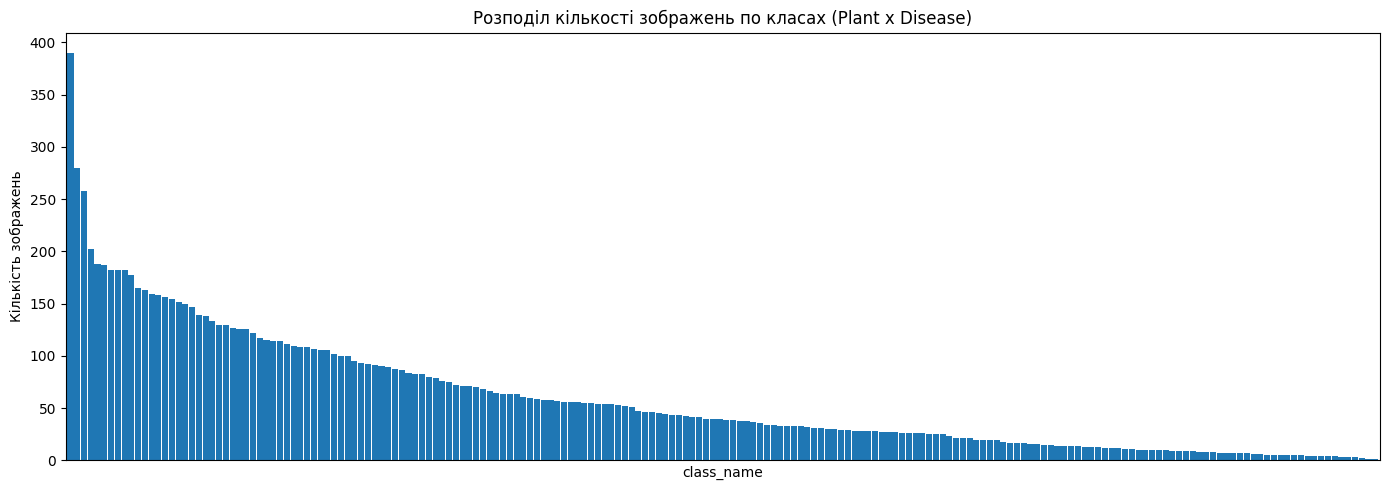

In [10]:
# Комбінований клас = Plant + Disease (фактичний таргет для класифікації)
meta['class_name'] = meta['Plant'].astype(str).str.strip() + " __ " + meta['Disease'].astype(str).str.strip()
n_classes = meta['class_name'].nunique()
print("Кількість унікальних класів (Plant x Disease):", n_classes)

class_counts = meta['class_name'].value_counts()
print("\nНайбільш представлені класи:\n", class_counts.head(10))
print("\nНайменш представлені класи:\n", class_counts.tail(10))

plt.figure(figsize=(14, 5))
class_counts.plot(kind='bar', width=0.9)
plt.title("Розподіл кількості зображень по класах (Plant x Disease)")
plt.xticks([])
plt.ylabel("Кількість зображень")
plt.tight_layout()
plt.show()


In [11]:
# Знаходимо реальні шляхи до файлів зображень: спробуємо зіставити 'Name' з фактичними файлами
image_files = glob.glob(os.path.join(DATA_ROOT, "**", "images", "**", "*.*"), recursive=True)
image_files = [f for f in image_files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
print("Знайдено файлів зображень:", len(image_files))

# Індекс: basename -> full path (без розширення теж, про всяк випадок)
basename_to_path = {os.path.basename(f): f for f in image_files}
stem_to_path = {}
for f in image_files:
    stem_to_path.setdefault(Path(f).stem, f)

def resolve_image_path(name):
    if name in basename_to_path:
        return basename_to_path[name]
    stem = Path(str(name)).stem
    return stem_to_path.get(stem, None)

meta['filepath'] = meta['Name'].apply(resolve_image_path)
missing = meta['filepath'].isna().sum()
print(f"Не знайдено файлів для {missing} / {len(meta)} рядків метаданих ({missing/len(meta)*100:.1f}%).")
meta_resolved = meta.dropna(subset=['filepath']).reset_index(drop=True)
print("Залишилось валідних рядків:", len(meta_resolved))


Знайдено файлів зображень: 11458
Не знайдено файлів для 0 / 11458 рядків метаданих (0.0%).
Залишилось валідних рядків: 11458


In [12]:
# Аналогічно для масок (annotations)
mask_files = glob.glob(os.path.join(DATA_ROOT, "**", "annotations", "**", "*.*"), recursive=True)
mask_files = [f for f in mask_files if f.lower().endswith((".png", ".jpg", ".jpeg"))]
mask_stem_to_path = {}
for f in mask_files:
    mask_stem_to_path.setdefault(Path(f).stem, f)

def resolve_mask_path(name):
    stem = Path(str(name)).stem
    return mask_stem_to_path.get(stem, None)

meta_resolved['maskpath'] = meta_resolved['Name'].apply(resolve_mask_path)
print("Масок знайдено для:", meta_resolved['maskpath'].notna().sum(), "/", len(meta_resolved))


Масок знайдено для: 11458 / 11458


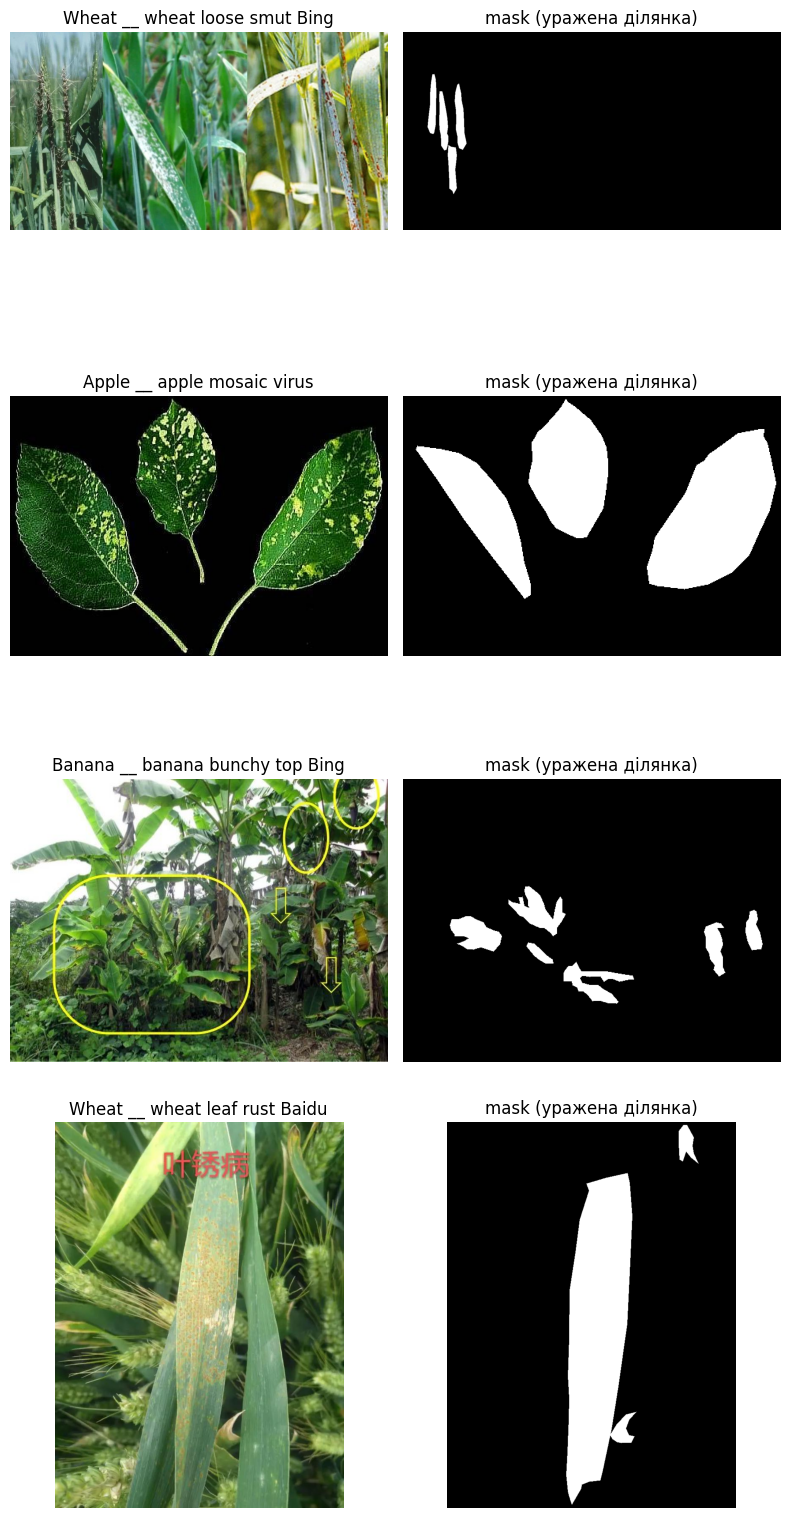

In [13]:
# Візуалізація кількох прикладів: зображення + маска ураженої ділянки
sample_rows = meta_resolved[meta_resolved['maskpath'].notna()].sample(min(4, len(meta_resolved)), random_state=SEED)

fig, axes = plt.subplots(len(sample_rows), 2, figsize=(8, 4 * len(sample_rows)))
if len(sample_rows) == 1:
    axes = axes[None, :]

for i, (_, row) in enumerate(sample_rows.iterrows()):
    img = cv2.cvtColor(cv2.imread(row['filepath']), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(row['maskpath'], cv2.IMREAD_GRAYSCALE)
    axes[i, 0].imshow(img); axes[i, 0].set_title(row['class_name']); axes[i, 0].axis('off')
    axes[i, 1].imshow(mask, cmap='gray'); axes[i, 1].set_title("mask (уражена ділянка)"); axes[i, 1].axis('off')

plt.tight_layout()
plt.show()


## 5. Підготовка спліту та кодування класів

In [14]:
# Прибираємо надто рідкісні класи (< 5 зображень) — інакше stratified split і ROC-AUC ламаються
vc = meta_resolved['class_name'].value_counts()
valid_classes = vc[vc >= 5].index
meta_final = meta_resolved[meta_resolved['class_name'].isin(valid_classes)].reset_index(drop=True)
print(f"Класів після фільтрації: {meta_final['class_name'].nunique()} "
      f"(відкинуто {vc.shape[0] - valid_classes.shape[0]} рідкісних класів)")

le = LabelEncoder()
meta_final['label_id'] = le.fit_transform(meta_final['class_name'])
NUM_CLASSES = len(le.classes_)
print("NUM_CLASSES =", NUM_CLASSES)

# Використовуємо офіційний спліт Training/Test, якщо є; з train виділяємо валідацію
if 'Training/Test' in meta_final.columns:
    train_full = meta_final[meta_final['Training/Test'].str.lower().str.contains('train', na=False)].reset_index(drop=True)
    test_df   = meta_final[meta_final['Training/Test'].str.lower().str.contains('test', na=False)].reset_index(drop=True)
else:
    train_full, test_df = train_test_split(meta_final, test_size=0.15, stratify=meta_final['label_id'], random_state=SEED)

train_df, val_df = train_test_split(
    train_full, test_size=0.15, stratify=train_full['label_id'], random_state=SEED
)

print("Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))


Класів після фільтрації: 183 (відкинуто 11 рідкісних класів)
NUM_CLASSES = 183
Train: 7766 Val: 1371 Test: 2288


## 6. PyTorch Dataset / DataLoader з аугментаціями

In [31]:
IMG_SIZE = 224
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

def get_transforms(aug_strength="medium"):
    if aug_strength == "light":
        train_tf = A.Compose([
            # Для RandomResizedCrop у нових версіях — тільки size=(H, W)
            A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.85, 1.0)),
            A.HorizontalFlip(p=0.5),
            A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
            ToTensorV2(),
        ])
    elif aug_strength == "heavy":
        train_tf = A.Compose([
            A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.6, 1.0)),
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.2),
            A.Rotate(limit=25, p=0.6),
            A.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05, p=0.7),
            A.CoarseDropout(
                num_holes_range=(1, 8),
                hole_height_range=(8, 24),
                hole_width_range=(8, 24),
                p=0.4
            ),
            A.GaussNoise(p=0.2),
            A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
            ToTensorV2(),
        ])
    else:  # medium (default)
        train_tf = A.Compose([
            A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.7, 1.0)),
            A.HorizontalFlip(p=0.5),
            A.Rotate(limit=15, p=0.5),
            A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02, p=0.5),
            A.CoarseDropout(
                num_holes_range=(1, 4),
                hole_height_range=(8, 20),
                hole_width_range=(8, 20),
                p=0.3
            ),
            A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
            ToTensorV2(),
        ])

    eval_tf = A.Compose([
        # Для Resize передаємо і height/width, і size для сумісності
        A.Resize(height=IMG_SIZE, width=IMG_SIZE),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])
    return train_tf, eval_tf


class PlantSegDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = cv2.imread(row['filepath'])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        augmented = self.transform(image=image)
        image = augmented['image']
        label = int(row['label_id'])
        return image, label


def make_loaders(train_df, val_df, test_df, batch_size=32, aug_strength="medium", num_workers=2):
    train_tf, eval_tf = get_transforms(aug_strength)

    train_ds = PlantSegDataset(train_df, train_tf)
    val_ds   = PlantSegDataset(val_df, eval_tf)
    test_ds  = PlantSegDataset(test_df, eval_tf)

    # Балансування класів через WeightedRandomSampler
    class_sample_count = train_df['label_id'].value_counts().sort_index()
    weights_per_class = 1.0 / class_sample_count
    sample_weights = train_df['label_id'].map(weights_per_class).values
    sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

    # persistent_workers=False (default) + явний del/gc.collect() у train_model прибирають
    # шумний "Exception ignored in _MultiProcessingDataLoaderIter.__del__" наприкінці trial.
    train_loader = DataLoader(train_ds, batch_size=batch_size, sampler=sampler,
                               num_workers=num_workers, pin_memory=True, drop_last=True,
                               persistent_workers=False)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                             num_workers=num_workers, pin_memory=True,
                             persistent_workers=False)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False,
                              num_workers=num_workers, pin_memory=True,
                              persistent_workers=False)
    return train_loader, val_loader, test_loader

print("Dataset/DataLoader готові.")


Dataset/DataLoader готові.


## 7. Модель, тренувальний та оцінювальний цикл (з повним набором метрик)

In [16]:
def build_model(backbone_name="efficientnet_b0", num_classes=NUM_CLASSES,
                 freeze_backbone=False, dropout=0.3):
    model = timm.create_model(backbone_name, pretrained=True, num_classes=0)  # без голови

    # ВАЖЛИВО: model.num_features іноді не збігається з реальним розміром вихідного вектора
    # (напр. MobileNetV3 в timm заявляє 960, а фактичний forward повертає 1280, або навпаки
    # залежно від версії). Тому визначаємо feat_dim динамічним forward-пасом замість того,
    # щоб довіряти атрибуту -- це і спричиняло "shapes cannot be multiplied" помилку.
    model.eval()
    with torch.no_grad():
        dummy = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)
        feat_dim = model(dummy).shape[1]

    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False

    classifier = nn.Sequential(
        nn.Dropout(dropout),
        nn.Linear(feat_dim, num_classes)
    )

    full_model = nn.Sequential(model, classifier)
    return full_model


def build_optimizer(model, opt_name="adamw", lr=3e-4, weight_decay=1e-4):
    if opt_name == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif opt_name == "adam":
        return torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif opt_name == "sgd":
        return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay, nesterov=True)
    else:
        raise ValueError(opt_name)


def build_scheduler(optimizer, sched_name, epochs, steps_per_epoch):
    if sched_name == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * steps_per_epoch)
    elif sched_name == "step":
        return torch.optim.lr_scheduler.StepLR(optimizer, step_size=max(1, epochs // 3) * steps_per_epoch, gamma=0.3)
    elif sched_name == "none":
        return None
    else:
        raise ValueError(sched_name)


In [17]:
def compute_metrics(y_true, y_pred, y_proba, num_classes):
    acc = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0)
    f1_weighted = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    precision_macro = precision_score(y_true, y_pred, average='macro', zero_division=0)
    recall_macro = recall_score(y_true, y_pred, average='macro', zero_division=0)

    try:
        # ВАЖЛИВО: labels має покривати ВСІ класи (0..num_classes-1), а не лише присутні
        # в цій епосі/батчі -- інакше розмірність y_proba (num_classes стовпців) не
        # збігається з labels, sklearn кидає виняток, і ми завжди тихо отримуємо nan.
        roc_auc = roc_auc_score(
            y_true, y_proba, multi_class='ovr', average='macro',
            labels=list(range(num_classes))
        )
    except Exception:
        # Фолбек: якщо якийсь клас взагалі відсутній у y_true цієї епохи (типово на
        # ранніх епохах з малою валідаційною вибіркою), рахуємо AUC тільки для класів,
        # що реально присутні, і усереднюємо вручну замість nan.
        present_classes = sorted(set(y_true))
        aucs = []
        y_true_arr = np.asarray(y_true)
        for c in present_classes:
            try:
                y_bin = (y_true_arr == c).astype(int)
                if y_bin.sum() == 0 or y_bin.sum() == len(y_bin):
                    continue
                aucs.append(roc_auc_score(y_bin, y_proba[:, c]))
            except Exception:
                continue
        roc_auc = float(np.mean(aucs)) if aucs else float('nan')

    return {
        "accuracy": acc,
        "f1_macro": f1_macro,
        "f1_weighted": f1_weighted,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "roc_auc_macro_ovr": roc_auc,
    }


def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, scaler=None, train=True):
    model.train() if train else model.eval()
    total_loss = 0.0
    all_labels, all_preds, all_probs = [], [], []

    context = torch.enable_grad() if train else torch.no_grad()
    with context:
        for images, labels in tqdm(loader, leave=False):
            images, labels = images.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)

            if train:
                optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(DEVICE.type, enabled=(scaler is not None)):
                logits = model(images)
                loss = criterion(logits, labels)

            if train:
                if scaler is not None:
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    optimizer.step()
                if scheduler is not None:
                    scheduler.step()

            total_loss += loss.item() * images.size(0)
            probs = F.softmax(logits.detach(), dim=1).cpu().numpy()
            preds = probs.argmax(axis=1)

            all_labels.extend(labels.cpu().numpy().tolist())
            all_preds.extend(preds.tolist())
            all_probs.append(probs)

    all_probs = np.concatenate(all_probs, axis=0)
    avg_loss = total_loss / len(loader.dataset)
    metrics = compute_metrics(all_labels, all_preds, all_probs, NUM_CLASSES)
    metrics["loss"] = avg_loss
    return metrics, np.array(all_labels), np.array(all_preds), all_probs


In [18]:
def train_model(config, train_df, val_df, verbose=True):
    '''Тренує одну конфігурацію. config = dict з гіперпараметрами. Повертає history + модель.'''
    train_loader, val_loader, _ = make_loaders(
        train_df, val_df, val_df,  # test_loader тут не використовується
        batch_size=config.get("batch_size", 32),
        aug_strength=config.get("aug_strength", "medium"),
    )

    model = build_model(
        backbone_name=config.get("backbone", "efficientnet_b0"),
        freeze_backbone=config.get("freeze_backbone", False),
        dropout=config.get("dropout", 0.3),
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss(label_smoothing=config.get("label_smoothing", 0.1))
    optimizer = build_optimizer(model, config.get("optimizer", "adamw"),
                                 lr=config.get("lr", 3e-4), weight_decay=config.get("weight_decay", 1e-4))
    epochs = config.get("epochs", 8)
    scheduler = build_scheduler(optimizer, config.get("scheduler", "cosine"), epochs, len(train_loader))
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=(DEVICE.type == "cuda"))

    history = {"train_loss": [], "val_loss": [], "val_accuracy": [], "val_f1_macro": [], "val_roc_auc": []}
    best_score = -1
    best_state = None
    patience, patience_counter = config.get("patience", 5), 0

    for epoch in range(epochs):
        train_metrics, *_ = run_epoch(model, train_loader, criterion, optimizer, scheduler, scaler, train=True)
        val_metrics, y_true, y_pred, y_proba = run_epoch(model, val_loader, criterion, train=False)

        history["train_loss"].append(train_metrics["loss"])
        history["val_loss"].append(val_metrics["loss"])
        history["val_accuracy"].append(val_metrics["accuracy"])
        history["val_f1_macro"].append(val_metrics["f1_macro"])
        history["val_roc_auc"].append(val_metrics["roc_auc_macro_ovr"])

        composite = np.nanmean([val_metrics["accuracy"], val_metrics["f1_macro"], val_metrics["roc_auc_macro_ovr"]])

        if verbose:
            print(f"  Epoch {epoch+1}/{epochs} | train_loss={train_metrics['loss']:.4f} "
                  f"val_loss={val_metrics['loss']:.4f} acc={val_metrics['accuracy']:.4f} "
                  f"f1_macro={val_metrics['f1_macro']:.4f} roc_auc={val_metrics['roc_auc_macro_ovr']:.4f} "
                  f"| composite={composite:.4f}")

        if composite > best_score:
            best_score = composite
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                if verbose:
                    print("  Early stopping.")
                break

    model.load_state_dict(best_state)

    # Прибираємо loader'и/воркери одразу після trial -- зменшує шум від DataLoader
    # multiprocessing __del__ і звільняє GPU-пам'ять перед наступною конфігурацією.
    del train_loader, val_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return model, history, best_score


## 8. Stratified K-Fold крос-валідація (на train+val частині)

In [19]:
def cross_validate(config, full_train_df, k=3):
    '''Швидка k-fold крос-валідація для оцінки стабільності конфігурації.
    k=3 за замовчуванням заради часу на Colab; збільште до 5 за потреби.'''
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)
    fold_scores = []

    for fold, (tr_idx, va_idx) in enumerate(skf.split(full_train_df, full_train_df['label_id'])):
        print(f"--- Fold {fold+1}/{k} ---")
        tr_fold = full_train_df.iloc[tr_idx]
        va_fold = full_train_df.iloc[va_idx]

        cfg_cv = dict(config)
        cfg_cv["epochs"] = min(config.get("epochs", 8), 5)  # коротші фолди для швидкості
        _, history, best_score = train_model(cfg_cv, tr_fold, va_fold, verbose=False)
        print(f"Fold {fold+1} composite score: {best_score:.4f}")
        fold_scores.append(best_score)

    print(f"\nCV mean composite score: {np.mean(fold_scores):.4f} +/- {np.std(fold_scores):.4f}")
    return fold_scores

# Приклад запуску (можна закоментувати, щоб зекономити час):
# cv_scores = cross_validate({"backbone": "efficientnet_b0", "epochs": 5}, train_df, k=3)


## 9. Автоматичний пошук по 10 конфігураціях (до 95% або 10 спроб)

In [32]:
HPO_CONFIGS = [
    {"name": "trial_01_effnetb0_adamw",      "backbone": "efficientnet_b0",  "optimizer": "adamw", "lr": 3e-4, "scheduler": "cosine", "aug_strength": "medium", "label_smoothing": 0.1, "freeze_backbone": False, "epochs": 8},
    {"name": "trial_02_effnetb0_adam_low",   "backbone": "efficientnet_b0",  "optimizer": "adam",  "lr": 1e-4, "scheduler": "cosine", "aug_strength": "light",  "label_smoothing": 0.0, "freeze_backbone": False, "epochs": 8},
    {"name": "trial_03_resnet50_sgd",        "backbone": "resnet50",         "optimizer": "sgd",   "lr": 1e-2, "scheduler": "step",   "aug_strength": "medium", "label_smoothing": 0.1, "freeze_backbone": False, "epochs": 8},
    {"name": "trial_04_effnetb3_adamw",      "backbone": "efficientnet_b3",  "optimizer": "adamw", "lr": 3e-4, "scheduler": "cosine", "aug_strength": "medium", "label_smoothing": 0.1, "freeze_backbone": False, "epochs": 8},
    {"name": "trial_05_mobilenetv3_adamw",   "backbone": "mobilenetv3_large_100", "optimizer": "adamw", "lr": 5e-4, "scheduler": "cosine", "aug_strength": "light", "label_smoothing": 0.1, "freeze_backbone": False, "epochs": 8},
    {"name": "trial_06_effnetb0_heavyaug",   "backbone": "efficientnet_b0",  "optimizer": "adamw", "lr": 3e-4, "scheduler": "cosine", "aug_strength": "heavy",  "label_smoothing": 0.1, "freeze_backbone": False, "epochs": 8},
    {"name": "trial_07_resnet50_adamw",      "backbone": "resnet50",         "optimizer": "adamw", "lr": 1e-4, "scheduler": "cosine", "aug_strength": "medium", "label_smoothing": 0.2, "freeze_backbone": False, "epochs": 8},
    {"name": "trial_08_effnetb0_frozen",     "backbone": "efficientnet_b0",  "optimizer": "adamw", "lr": 1e-3, "scheduler": "cosine", "aug_strength": "medium", "label_smoothing": 0.1, "freeze_backbone": True,  "epochs": 8},
    {"name": "trial_09_convnext_tiny",       "backbone": "convnext_tiny",    "optimizer": "adamw", "lr": 2e-4, "scheduler": "cosine", "aug_strength": "medium", "label_smoothing": 0.1, "freeze_backbone": False, "epochs": 8},
    {"name": "trial_10_effnetb3_longer",     "backbone": "efficientnet_b3",  "optimizer": "adamw", "lr": 2e-4, "scheduler": "cosine", "aug_strength": "heavy",  "label_smoothing": 0.1, "freeze_backbone": False, "epochs": 10},
]

TARGET_SCORE = 0.95
MAX_TRIALS = 10

results_log = []
best_overall = {"score": -1, "model": None, "config": None, "history": None}

for i, cfg in enumerate(HPO_CONFIGS[:MAX_TRIALS], start=1):
    print(f"\n========== Trial {i}/{MAX_TRIALS}: {cfg['name']} ==========")
    print(cfg)
    t0 = time.time()
    model, history, score = train_model(cfg, train_df, val_df, verbose=True)
    elapsed = time.time() - t0
    print(f"Trial {i} best composite score = {score:.4f} (за {elapsed/60:.1f} хв)")

    results_log.append({
        "trial": i, "name": cfg["name"], "config": cfg,
        "composite_score": score, "history": history, "elapsed_min": elapsed / 60,
    })

    if score > best_overall["score"]:
        best_overall = {"score": score, "model": model, "config": cfg, "history": history, "trial": i}

    if score >= TARGET_SCORE:
        print(f"\n🎯 Досягнуто цільового composite score >= {TARGET_SCORE}. Зупиняємось на trial {i}.")
        break

print("\n\n========== ПІДСУМОК ==========")
summary_df = pd.DataFrame([
    {"trial": r["trial"], "name": r["name"], "composite_score": r["composite_score"], "elapsed_min": r["elapsed_min"]}
    for r in results_log
]).sort_values("composite_score", ascending=False)
print(summary_df.to_string(index=False))
print(f"\nНайкраща конфігурація: trial {best_overall['trial']} — {best_overall['config']['name']} "
      f"(composite score = {best_overall['score']:.4f})")



========== Trial 1/10: trial_01_effnetb0_adamw ==========
{'name': 'trial_01_effnetb0_adamw', 'backbone': 'efficientnet_b0', 'optimizer': 'adamw', 'lr': 0.0003, 'scheduler': 'cosine', 'aug_strength': 'medium', 'label_smoothing': 0.1, 'freeze_backbone': False, 'epochs': 8}


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

  0%|          | 0/242 [00:00<?, ?it/s]

  0%|          | 0/43 [00:00<?, ?it/s]

  Epoch 1/8 | train_loss=3.7139 val_loss=3.0019 acc=0.3406 f1_macro=0.2203 roc_auc=0.9727 | composite=0.5112


... (272 outputs left out)

  0%|          | 0/242 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78075017d120>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78075017d120>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  0%|          | 0/43 [00:00<?, ?it/s]

  Epoch 10/10 | train_loss=1.5175 val_loss=2.2155 acc=0.5339 f1_macro=0.3815 roc_auc=0.9737 | composite=0.6297
Trial 10 best composite score = 0.6339 (за 20.8 хв)


========== ПІДСУМОК ==========
 trial                       name  composite_score  elapsed_min
     9     trial_09_convnext_tiny         0.663416    15.867420
     4    trial_04_effnetb3_adamw         0.649056    17.034426
     1    trial_01_effnetb0_adamw         0.646987    15.874826
    10   trial_10_effnetb3_longer         0.633869    20.775183
     5 trial_05_mobilenetv3_adamw         0.632843    14.645273
     6 trial_06_effnetb0_heavyaug         0.629945    15.509579
     2 trial_02_effnetb0_adam_low         0.604204    14.089218
     8   trial_08_effnetb0_frozen         0.529571    13.526609
     7    trial_07_resnet50_adamw         0.505645    14.848857
     3      trial_03_resnet50_sgd         0.435709    15.403105

Найкраща конфігурація: trial 9 — trial_09_convnext_tiny (composite score = 0.6634)


## 10. Збереження найкращої моделі (для локального відтворення)

In [33]:
BEST_MODEL_PATH = os.path.join(CKPT_DIR, "best_model.pth")
BEST_CONFIG_PATH = os.path.join(CKPT_DIR, "best_config.json")
LABEL_ENCODER_PATH = os.path.join(CKPT_DIR, "label_encoder.json")

torch.save(best_overall["model"].state_dict(), BEST_MODEL_PATH)

with open(BEST_CONFIG_PATH, "w") as f:
    json.dump({
        "config": best_overall["config"],
        "composite_score": best_overall["score"],
        "num_classes": NUM_CLASSES,
        "img_size": IMG_SIZE,
        "imagenet_mean": IMAGENET_MEAN,
        "imagenet_std": IMAGENET_STD,
    }, f, indent=2)

with open(LABEL_ENCODER_PATH, "w") as f:
    json.dump(list(le.classes_), f, ensure_ascii=False, indent=2)

print("Збережено:")
print(" -", BEST_MODEL_PATH)
print(" -", BEST_CONFIG_PATH)
print(" -", LABEL_ENCODER_PATH)
print("\nЩоб завантажити локально: скачайте всі три файли з", CKPT_DIR)


Збережено:
 - /content/drive/MyDrive/plantseg_project/checkpoints/best_model.pth
 - /content/drive/MyDrive/plantseg_project/checkpoints/best_config.json
 - /content/drive/MyDrive/plantseg_project/checkpoints/label_encoder.json

Щоб завантажити локально: скачайте всі три файли з /content/drive/MyDrive/plantseg_project/checkpoints


In [34]:
# Функція для локального відтворення (працює і в цьому ноутбуці, і локально за наявності тих самих файлів)
def load_trained_model(model_path, config_path, label_encoder_path, device=None):
    device = device or (torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu"))
    with open(config_path) as f:
        meta = json.load(f)
    with open(label_encoder_path) as f:
        classes = json.load(f)

    model = build_model(
        backbone_name=meta["config"]["backbone"],
        num_classes=meta["num_classes"],
        freeze_backbone=False,
        dropout=meta["config"].get("dropout", 0.3),
    )
    state_dict = torch.load(model_path, map_location=device)
    model.load_state_dict(state_dict)
    model.to(device).eval()
    return model, classes, meta

print("Функція load_trained_model() готова для локального відтворення.")


Функція load_trained_model() готова для локального відтворення.


## 11. Тест на випадковому фото (незалежна перевірка)

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


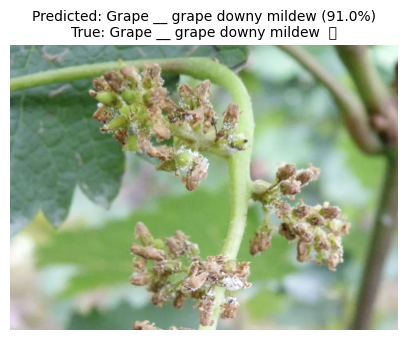

Top-5 передбачень:
  Grape __ grape downy mildew                                  90.95%
  Apple __ apple rust                                           0.62%
  Cauliflower __ cauliflower bacterial soft rot Bing            0.54%
  Blueberry __ blueberry botrytis blight Google                 0.49%
  Apple __ apple scab                                           0.33%


In [35]:
def predict_image(model, image_path_or_array, classes, img_size=IMG_SIZE,
                   mean=IMAGENET_MEAN, std=IMAGENET_STD, device=None, topk=5):
    device = device or DEVICE
    if isinstance(image_path_or_array, str):
        image = cv2.cvtColor(cv2.imread(image_path_or_array), cv2.COLOR_BGR2RGB)
    else:
        image = image_path_or_array

    tf = A.Compose([A.Resize(img_size, img_size), A.Normalize(mean=mean, std=std), ToTensorV2()])
    tensor = tf(image=image)['image'].unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        logits = model(tensor)
        probs = F.softmax(logits, dim=1).cpu().numpy()[0]

    top_idx = probs.argsort()[::-1][:topk]
    results = [(classes[i], float(probs[i])) for i in top_idx]
    return results, image


def test_random_photo(model, classes, source_df=None, custom_path=None):
    '''source_df: якщо задано (напр. test_df), бере випадкове реальне фото з датасету
    та порівнює прогноз із справжньою міткою. custom_path: шлях до власного фото (без відомого лейбла).'''
    if custom_path is not None:
        results, image = predict_image(model, custom_path, classes)
        true_label = None
    else:
        row = source_df.sample(1, random_state=random.randint(0, 100000)).iloc[0]
        results, image = predict_image(model, row['filepath'], classes)
        true_label = row['class_name']

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    title = f"Predicted: {results[0][0]} ({results[0][1]*100:.1f}%)"
    if true_label is not None:
        title += f"\nTrue: {true_label}"
        title += "  ✅" if true_label == results[0][0] else "  ❌"
    plt.title(title, fontsize=10)
    plt.axis('off')
    plt.show()

    print("Top-5 передбачень:")
    for cls, p in results:
        print(f"  {cls:60s} {p*100:5.2f}%")

    return results, true_label

# Приклад запуску на випадковому фото з test-спліту:
_ = test_random_photo(best_overall["model"], list(le.classes_), source_df=test_df)


In [36]:
# Тест на ВЛАСНОМУ завантаженому фото
from google.colab import files as colab_files

def test_uploaded_photo(model, classes):
    uploaded = colab_files.upload()
    for fname in uploaded.keys():
        results, image = predict_image(model, fname, classes)
        plt.figure(figsize=(5, 5))
        plt.imshow(image)
        plt.title(f"Predicted: {results[0][0]} ({results[0][1]*100:.1f}%)", fontsize=10)
        plt.axis('off')
        plt.show()
        print("Top-5 передбачень:")
        for cls, p in results:
            print(f"  {cls:60s} {p*100:5.2f}%")

# Розкоментуйте, щоб завантажити своє фото з комп'ютера:
# test_uploaded_photo(best_overall["model"], list(le.classes_))


## 12. Повний звіт метрик найкращої моделі (на test-спліті)

In [37]:
_, _, test_loader = make_loaders(train_df, val_df, test_df, batch_size=32,
                                  aug_strength=best_overall["config"].get("aug_strength", "medium"))

criterion = nn.CrossEntropyLoss()
test_metrics, y_true, y_pred, y_proba = run_epoch(best_overall["model"], test_loader, criterion, train=False)

print("=== TEST METRICS (найкраща модель) ===")
for k, v in test_metrics.items():
    print(f"{k:20s}: {v:.4f}")


  0%|          | 0/72 [00:00<?, ?it/s]

=== TEST METRICS (найкраща модель) ===
accuracy            : 0.6097
f1_macro            : 0.4391
f1_weighted         : 0.6075
precision_macro     : 0.4612
recall_macro        : 0.4414
roc_auc_macro_ovr   : 0.9735
loss                : 1.4817


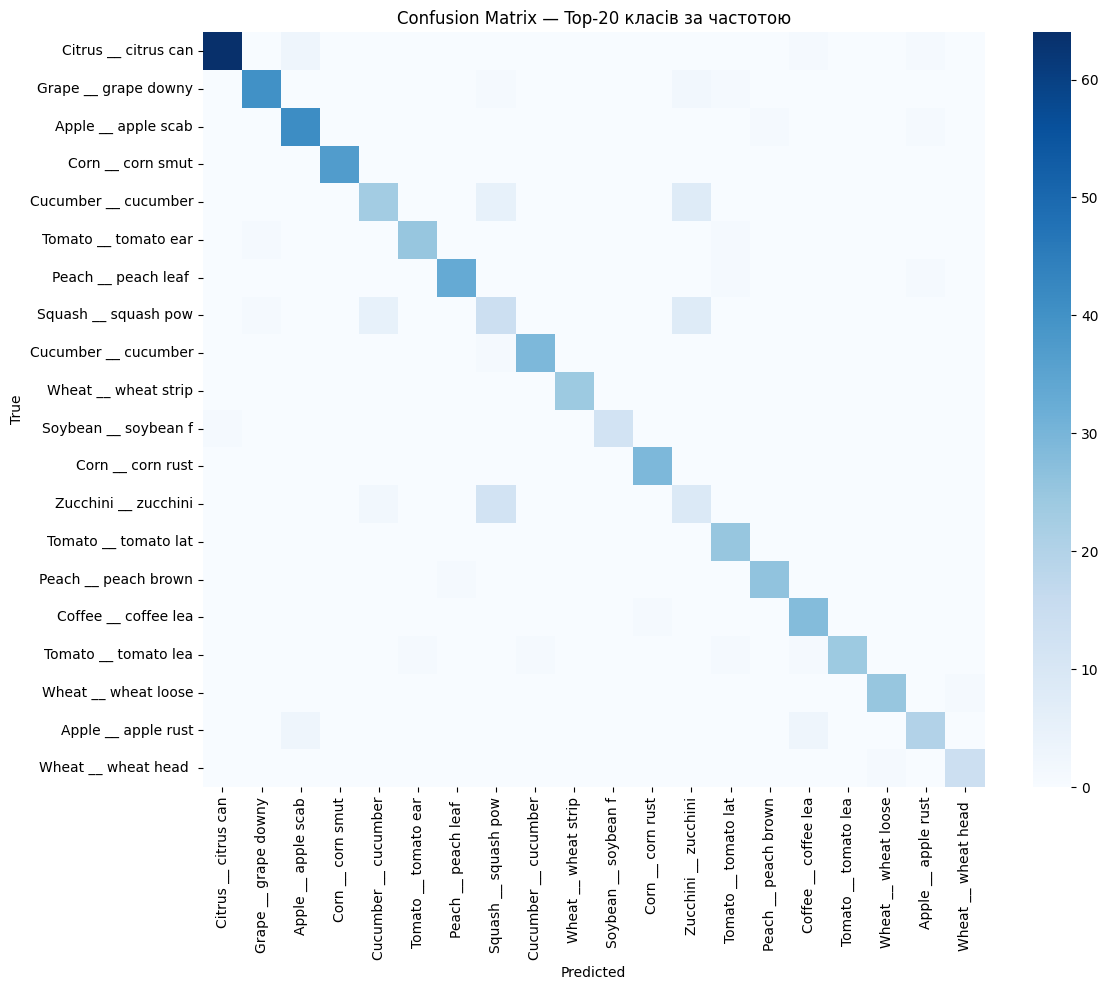

In [40]:
# Confusion matrix (топ-20 найчастіших класів, повна 115x115 нечитабельна)
top_classes_idx = pd.Series(y_true).value_counts().head(20).index.tolist()
mask = np.isin(y_true, top_classes_idx)
cm = confusion_matrix(y_true[mask], y_pred[mask], labels=top_classes_idx)

plt.figure(figsize=(12, 10))
labels_short = [le.classes_[i][:20] for i in top_classes_idx]
sns.heatmap(cm, annot=False, cmap='Blues', xticklabels=labels_short, yticklabels=labels_short)
plt.xticks(rotation=90); plt.yticks(rotation=0)
plt.title("Confusion Matrix — Top-20 класів за частотою")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout()
plt.show()


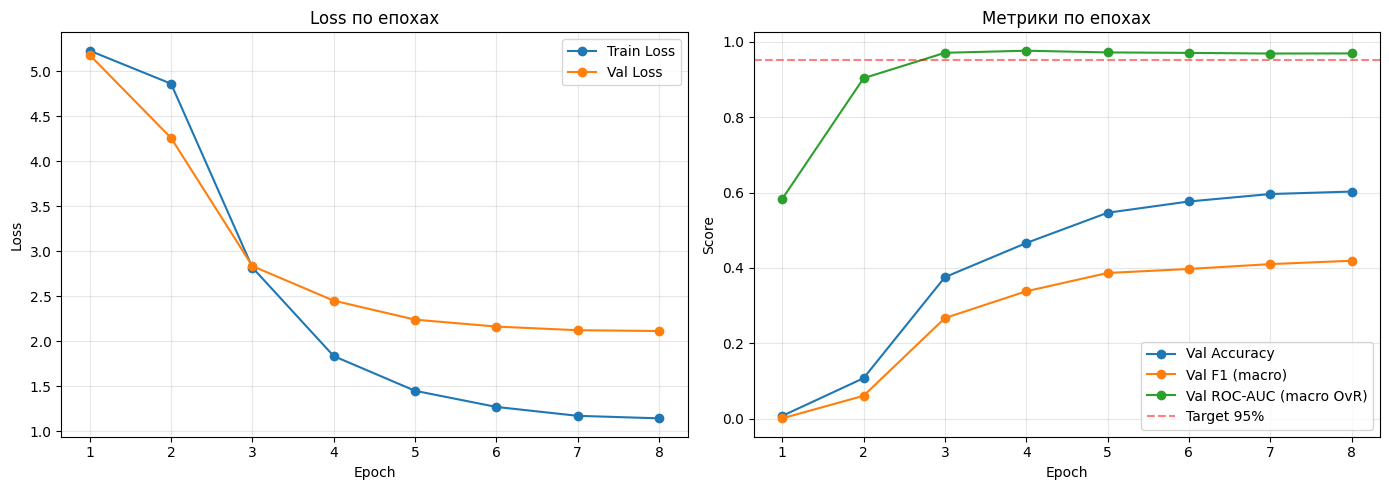

In [41]:
# Динаміка метрик по епохах для найкращого trial
history = best_overall["history"]
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history["train_loss"], label="Train Loss", marker='o')
axes[0].plot(epochs_range, history["val_loss"], label="Val Loss", marker='o')
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend(); axes[0].set_title("Loss по епохах")
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, history["val_accuracy"], label="Val Accuracy", marker='o')
axes[1].plot(epochs_range, history["val_f1_macro"], label="Val F1 (macro)", marker='o')
axes[1].plot(epochs_range, history["val_roc_auc"], label="Val ROC-AUC (macro OvR)", marker='o')
axes[1].axhline(0.95, color='red', linestyle='--', alpha=0.5, label="Target 95%")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Score"); axes[1].legend(); axes[1].set_title("Метрики по епохах")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


/tmp/ipykernel_3335/1406120912.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(summary_df["name"], rotation=75, ha='right')


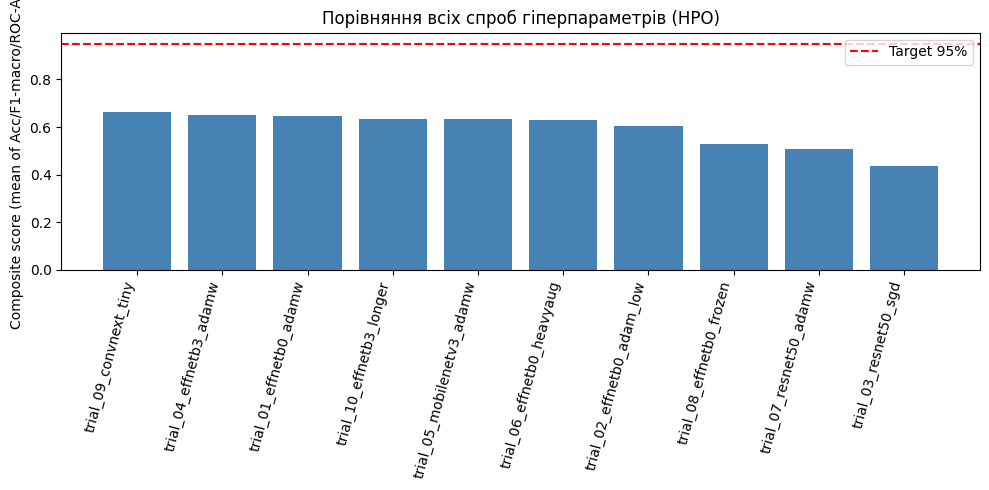

,trial,name,composite_score,elapsed_min
8,9,trial_09_convnext_tiny,0.663416,15.867420
3,4,trial_04_effnetb3_adamw,0.649056,17.034426
0,1,trial_01_effnetb0_adamw,0.646987,15.874826
9,10,trial_10_effnetb3_longer,0.633869,20.775183
4,5,trial_05_mobilenetv3_adamw,0.632843,14.645273
5,6,trial_06_effnetb0_heavyaug,0.629945,15.509579
1,2,trial_02_effnetb0_adam_low,0.604204,14.089218
7,8,trial_08_effnetb0_frozen,0.529571,13.526609
6,7,trial_07_resnet50_adamw,0.505645,14.848857
2,3,trial_03_resnet50_sgd,0.435709,15.403105


In [42]:
# Порівняння всіх 10 спроб HPO
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(summary_df["name"], summary_df["composite_score"], color='steelblue')
ax.axhline(0.95, color='red', linestyle='--', label="Target 95%")
ax.set_xticklabels(summary_df["name"], rotation=75, ha='right')
ax.set_ylabel("Composite score (mean of Acc/F1-macro/ROC-AUC)")
ax.set_title("Порівняння всіх спроб гіперпараметрів (HPO)")
ax.legend()
plt.tight_layout()
plt.show()

summary_df


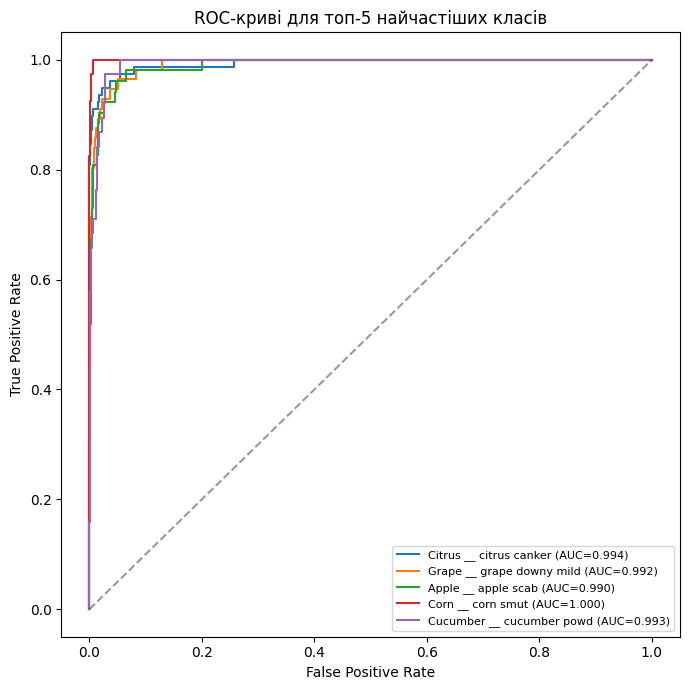

In [43]:
# ROC-криві для кількох найчастіших класів (one-vs-rest)
from sklearn.preprocessing import label_binarize

top5_idx = pd.Series(y_true).value_counts().head(5).index.tolist()
y_true_bin = label_binarize(y_true, classes=sorted(set(y_true)))

plt.figure(figsize=(7, 7))
for idx in top5_idx:
    class_pos = sorted(set(y_true)).index(idx)
    fpr, tpr, _ = __import__('sklearn.metrics', fromlist=['roc_curve']).roc_curve(y_true_bin[:, class_pos], y_proba[:, idx])
    auc_val = __import__('sklearn.metrics', fromlist=['auc']).auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{le.classes_[idx][:25]} (AUC={auc_val:.3f})")

plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC-криві для топ-5 найчастіших класів")
plt.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()


## Підсумок

- Найкраща модель збережена у `best_model.pth` (+ `best_config.json`, `label_encoder.json`) у `CKPT_DIR`.
- Для локального відтворення: скопіюйте ці три файли, встановіть `torch`, `timm`, `albumentations`,
  імпортуйте функції `build_model`, `predict_image`, `load_trained_model` (можна винести в окремий
  `inference.py`, якщо потрібно) і викликайте:

```python
model, classes, meta = load_trained_model("best_model.pth", "best_config.json", "label_encoder.json")
results, image = predict_image(model, "your_photo.jpg", classes)
```

- Якщо жодна з 10 спроб не досягла 95% (реалістично для 115 fine-grained класів на ~11K "живих" фото) —
  наступні кроки для покращення: більше епох на кращій конфігурації, ансамблювання топ-3 моделей,
  test-time augmentation (TTA), використання масок (`annotations/`) для focal-crop навколо ураженої
  ділянки перед класифікацією, або перехід на true segmentation-модель (U-Net/DeepLab) з masks як таргетом
  замість чистої класифікації.
